# HIGGS Classification with PySpark MLlib and Tableau

**Author:** Dongju Mun — A01712119

**Objective:** process the complete HIGGS dataset with PySpark, classify simulated particle events as signal (1) or background (0) with MLlib, evaluate held-out events, generate predictions, and communicate the results through Tableau dashboards.

## Dataset and sources

- [UCI HIGGS dataset](https://archive.ics.uci.edu/dataset/280/higgs): 11,000,000 events, 28 numeric features and a binary target. The downloaded file measured **2,816,407,858 bytes (2.816407858 decimal GB; 2.622984217 GiB)**. The decompressed CSV measured **8,035,497,980 bytes (8.035497980 decimal GB)**.
- [Official UCI physics download directory](https://mlphysics.ics.uci.edu/data/higgs/).
- The events were generated by Monte Carlo simulation. The classification target distinguishes simulated signal and background events.
- Whiteson, D. (2014). *HIGGS* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5V312. **License:** CC BY 4.0.
- [Apache Spark classification guide](https://spark.apache.org/docs/3.5.7/ml-classification-regression.html). `pyspark.ml` provides MLlib's DataFrame API.

The experiment uses a seeded 80/20 random holdout, which differs from the original UCI benchmark's last-500,000-row test split.


## 1. Colab environment configuration
The environment includes PySpark 3.5.7, the Python analysis dependencies, and a mounted Google Drive connection for saving the generated archives.


In [ ]:
%pip -q install pyspark==3.5.7 requests tqdm pandas matplotlib

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, sys, json, shutil, gzip, hashlib, time, platform
from pathlib import Path
from functools import reduce
import requests
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

if shutil.which("java") is None:
    import subprocess
    subprocess.run(["apt-get", "-qq", "update"], check=True)
    subprocess.run(["apt-get", "-qq", "install", "-y", "openjdk-17-jdk-headless"], check=True)
java_executable = Path(shutil.which("java")).resolve()
os.environ["JAVA_HOME"] = str(java_executable.parent.parent)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

from pyspark.sql import SparkSession, functions as F, types as T
from pyspark import StorageLevel
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.functions import vector_to_array

BASE = Path("/content/higgs_project")
DATA = BASE / "data"
EXPORT = BASE / "dashboard_exports"
for directory in [DATA, EXPORT]:
    directory.mkdir(parents=True, exist_ok=True)

spark = (SparkSession.builder.appName("HIGGS-BigData-Classification")
         .master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.sql.adaptive.enabled", "true")
         .config("spark.local.dir", str(BASE / "spark_temp"))
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
print("Python:", platform.python_version(), "Spark:", spark.version)
print("Java home:", os.environ["JAVA_HOME"])
print("Spark master:", spark.sparkContext.master)
print("Available disk (GiB):", round(shutil.disk_usage(BASE).free / 2**30, 2))


Python: 3.13.16 Spark: 3.5.7
Java home: /usr/lib/jvm/java-21-openjdk-amd64
Spark master: local[*]
Available disk (GiB): 111.61


**Architecture:** Spark runs locally on a single Colab machine with `local[*]`, using the available CPU cores. Large tables remain in Spark, with disk-backed persistence for the training, test and prediction tables.

## 2. Dataset download and size verification
The complete source is downloaded in chunks and decompressed on local disk. A temporary `.part` file is renamed after a completed download. The storage check requires at least 25 GiB of available disk for the source files and intermediate data. File sizes are recorded in bytes, decimal GB and binary GiB.


In [ ]:
URL = "https://mlphysics.ics.uci.edu/data/higgs/HIGGS.csv.gz"
GZ = DATA / "HIGGS.csv.gz"
CSV = DATA / "HIGGS.csv"

def download_file(url, destination):
    if destination.exists():
        print("Reusing:", destination.name)
        return
    if shutil.disk_usage(DATA).free < 25 * 2**30:
        raise RuntimeError("Insufficient disk space: at least 25 GiB is required.")
    temporary = destination.with_suffix(destination.suffix + ".part")
    # Incomplete transfers remain in the temporary file.
    with requests.get(url, stream=True, timeout=(30, 180)) as response:
        response.raise_for_status()
        expected = int(response.headers.get("Content-Length", 0))
        with temporary.open("wb") as target, tqdm(total=expected or None, unit="B", unit_scale=True) as bar:
            for chunk in response.iter_content(chunk_size=4 * 1024 * 1024):
                if chunk:
                    target.write(chunk)
                    bar.update(len(chunk))
    if expected and temporary.stat().st_size != expected:
        raise IOError("Incomplete download: received file size differs from Content-Length.")
    temporary.replace(destination)

download_file(URL, GZ)
assert GZ.stat().st_size >= 2**30, "Source file is smaller than the required 1 GiB."

if not CSV.exists():
    temporary_csv = CSV.with_suffix(".csv.part")
    # Streaming decompression does not load the dataset into RAM.
    # Reading to the end also checks gzip integrity.
    with gzip.open(GZ, "rb") as source, temporary_csv.open("wb") as target:
        shutil.copyfileobj(source, target, length=8 * 1024 * 1024)
    temporary_csv.replace(CSV)

size_report = {
    "dataset": "HIGGS", "download_url": URL,
    "compressed_bytes": GZ.stat().st_size,
    "csv_bytes": CSV.stat().st_size,
    "compressed_GB_decimal": GZ.stat().st_size / 1e9,
    "compressed_GiB": GZ.stat().st_size / 2**30,
    "csv_GB_decimal": CSV.stat().st_size / 1e9,
    "meets_1_GB_requirement": GZ.stat().st_size >= 1_000_000_000,
}
(EXPORT / "dataset_size_evidence.json").write_text(json.dumps(size_report, indent=2))
print(json.dumps(size_report, indent=2))


  0%|          | 0.00/2.82G [00:00<?, ?B/s]

{
  "dataset": "HIGGS",
  "download_url": "https://mlphysics.ics.uci.edu/data/higgs/HIGGS.csv.gz",
  "compressed_bytes": 2816407858,
  "csv_bytes": 8035497980,
  "compressed_GB_decimal": 2.816407858,
  "compressed_GiB": 2.622984217479825,
  "csv_GB_decimal": 8.03549798,
  "meets_1_GB_requirement": true
}


The uncompressed CSV supports partitioned Spark reads, whereas a single gzip stream cannot be split into independent input partitions. The size calculations use 1 GB = 1,000,000,000 bytes and 1 GiB = 1,073,741,824 bytes.

## 3. Data loading with an explicit schema
The source file has no header. Its first column is the target, followed by the 28 numerical features in UCI's documented order. An explicit schema avoids a separate schema-inference pass over the entire file.


In [ ]:
FEATURES = [
    "lepton_pt", "lepton_eta", "lepton_phi", "missing_energy_magnitude", "missing_energy_phi",
    "jet_1_pt", "jet_1_eta", "jet_1_phi", "jet_1_b_tag",
    "jet_2_pt", "jet_2_eta", "jet_2_phi", "jet_2_b_tag",
    "jet_3_pt", "jet_3_eta", "jet_3_phi", "jet_3_b_tag",
    "jet_4_pt", "jet_4_eta", "jet_4_phi", "jet_4_b_tag",
    "m_jj", "m_jjj", "m_lv", "m_jlv", "m_bb", "m_wbb", "m_wwbb"
]
COLUMNS = ["label"] + FEATURES
schema = T.StructType([T.StructField(c, T.DoubleType(), True) for c in COLUMNS])
raw = (spark.read.schema(schema).option("header", "false")
       .option("mode", "FAILFAST").csv(str(CSV)))
raw.printSchema()
raw.show(5, truncate=False)
print("CSV input partitions:", raw.rdd.getNumPartitions())


root
 |-- label: double (nullable = true)
 |-- lepton_pt: double (nullable = true)
 |-- lepton_eta: double (nullable = true)
 |-- lepton_phi: double (nullable = true)
 |-- missing_energy_magnitude: double (nullable = true)
 |-- missing_energy_phi: double (nullable = true)
 |-- jet_1_pt: double (nullable = true)
 |-- jet_1_eta: double (nullable = true)
 |-- jet_1_phi: double (nullable = true)
 |-- jet_1_b_tag: double (nullable = true)
 |-- jet_2_pt: double (nullable = true)
 |-- jet_2_eta: double (nullable = true)
 |-- jet_2_phi: double (nullable = true)
 |-- jet_2_b_tag: double (nullable = true)
 |-- jet_3_pt: double (nullable = true)
 |-- jet_3_eta: double (nullable = true)
 |-- jet_3_phi: double (nullable = true)
 |-- jet_3_b_tag: double (nullable = true)
 |-- jet_4_pt: double (nullable = true)
 |-- jet_4_eta: double (nullable = true)
 |-- jet_4_phi: double (nullable = true)
 |-- jet_4_b_tag: double (nullable = true)
 |-- m_jj: double (nullable = true)
 |-- m_jjj: double (nullable = 

## 4. Data quality checks and Parquet storage
The quality checks cover row counts, nulls, NaN, infinite values and labels outside 0 and 1. Rows with invalid required values are excluded before storage. No invalid rows were found in this execution, so all 11,000,000 events were retained.

Signed feature values are retained because some features describe directional quantities. Feature values remain in the supplied numerical scale. Repeated numerical records are not automatically treated as collection errors because the source does not provide an event identifier. The validated data are stored in Parquet for subsequent analysis and modeling.


In [ ]:
invalid_by_column = {
    c: (F.col(c).isNull() | F.isnan(F.col(c)) | (F.abs(F.col(c)) == float("inf")))
    for c in COLUMNS
}
any_invalid = reduce(lambda a, b: a | b, invalid_by_column.values()) | (~F.col("label").isin(0.0, 1.0))
quality = raw.agg(
    F.count("*").alias("raw_rows"),
    F.sum(F.when(any_invalid, 1).otherwise(0)).alias("invalid_rows"),
    *[F.sum(F.when(condition, 1).otherwise(0)).alias(c + "_invalid")
      for c, condition in invalid_by_column.items()]
).first().asDict()
assert quality["raw_rows"] == 11_000_000, "Input row count differs from the expected 11 million events."
quality["valid_rows"] = quality["raw_rows"] - quality["invalid_rows"]
print(json.dumps(quality, indent=2))
(EXPORT / "data_quality.json").write_text(json.dumps(quality, indent=2))

PARQUET = DATA / "clean_parquet"
(raw.filter(~any_invalid).repartition(16)
    .write.mode("overwrite").parquet(str(PARQUET)))
df = spark.read.parquet(str(PARQUET))
assert df.count() == quality["valid_rows"]
assert quality["valid_rows"] > 0
print("Valid rows:", quality["valid_rows"])
print("Parquet partitions:", df.rdd.getNumPartitions())


{
  "raw_rows": 11000000,
  "invalid_rows": 0,
  "label_invalid": 0,
  "lepton_pt_invalid": 0,
  "lepton_eta_invalid": 0,
  "lepton_phi_invalid": 0,
  "missing_energy_magnitude_invalid": 0,
  "missing_energy_phi_invalid": 0,
  "jet_1_pt_invalid": 0,
  "jet_1_eta_invalid": 0,
  "jet_1_phi_invalid": 0,
  "jet_1_b_tag_invalid": 0,
  "jet_2_pt_invalid": 0,
  "jet_2_eta_invalid": 0,
  "jet_2_phi_invalid": 0,
  "jet_2_b_tag_invalid": 0,
  "jet_3_pt_invalid": 0,
  "jet_3_eta_invalid": 0,
  "jet_3_phi_invalid": 0,
  "jet_3_b_tag_invalid": 0,
  "jet_4_pt_invalid": 0,
  "jet_4_eta_invalid": 0,
  "jet_4_phi_invalid": 0,
  "jet_4_b_tag_invalid": 0,
  "m_jj_invalid": 0,
  "m_jjj_invalid": 0,
  "m_lv_invalid": 0,
  "m_jlv_invalid": 0,
  "m_bb_invalid": 0,
  "m_wbb_invalid": 0,
  "m_wwbb_invalid": 0,
  "valid_rows": 11000000
}
Valid rows: 11000000
Parquet partitions: 8


## 5. Full-dataset descriptive analysis
Class counts, feature summaries, class-specific means and histograms are computed over all valid events. Only the small aggregate tables are converted to pandas for plotting or export.


In [ ]:
class_distribution = (df.groupBy("label").count()
    .withColumn("class_name", F.when(F.col("label") == 1, "Signal").otherwise("Background"))
    .withColumn("share", F.col("count") / F.lit(quality["valid_rows"])))
class_distribution.orderBy("label").show()
class_distribution.orderBy("label").toPandas().to_csv(EXPORT / "class_distribution.csv", index=False)
summary = df.select(FEATURES).summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")
summary.show(truncate=False)
summary.toPandas().to_csv(EXPORT / "feature_summary.csv", index=False)

# Grouped values for the managed dashboard: one row per class and feature.
means = df.groupBy("label").agg(*[F.avg(c).alias(c) for c in FEATURES]).toPandas()
feature_means = means.melt(id_vars="label", var_name="feature", value_name="mean_value")
feature_means.to_csv(EXPORT / "feature_means_by_class.csv", index=False)


+-----+-------+----------+------------------+
|label|  count|class_name|             share|
+-----+-------+----------+------------------+
|  0.0|5170877|Background|0.4700797272727273|
|  1.0|5829123|    Signal|0.5299202727272727|
+-----+-------+----------+------------------+

+-------+------------------+--------------------+----------------------+------------------------+---------------------+-------------------+----------------------+---------------------+------------------+-------------------+----------------------+----------------------+------------------+-------------------+---------------------+----------------------+------------------+-------------------+---------------------+----------------------+------------------+-------------------+-------------------+-------------------+-------------------+-------------------+------------------+-------------------+
|summary|lepton_pt         |lepton_eta          |lepton_phi            |missing_energy_magnitude|missing_energy_phi   |jet_1_pt

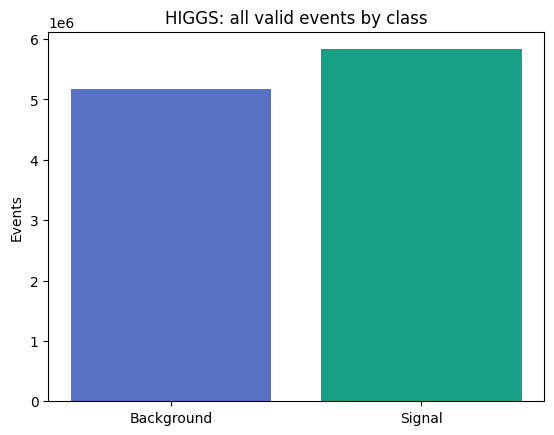

In [ ]:
# Exact distributed counts in 50 displayed bins across [0, 5].
# Values below/above the range go in the edge bins, explicitly marked below.
histograms = []
for feature in ["lepton_pt", "m_bb", "m_wwbb"]:
    bucket = F.greatest(F.lit(0), F.least(F.lit(49), F.floor(F.col(feature) / 0.1))).cast("int")
    table = (df.select("label", bucket.alias("bin_index"))
             .groupBy("label", "bin_index").count().toPandas())
    table["feature"] = feature
    table["bin_start"] = table["bin_index"] * 0.1
    table["bin_end"] = (table["bin_index"] + 1) * 0.1
    table["bin_label"] = table["bin_index"].map(
        lambda i: "<0.1 (includes negatives)" if i == 0 else
        ">=4.9" if i == 49 else f"{i/10:.1f} to {(i+1)/10:.1f}")
    histograms.append(table)
feature_histograms = pd.concat(histograms, ignore_index=True)
feature_histograms.to_csv(EXPORT / "feature_histograms.csv", index=False)

plot_data = class_distribution.orderBy("label").toPandas()
plt.bar(plot_data["class_name"], plot_data["count"], color=["#5870c4", "#16a085"])
plt.title("HIGGS: all valid events by class")
plt.ylabel("Events")
plt.show()


## 6. Training and test separation
A seeded random split assigns approximately 80% of the valid events to training and 20% to an unseen test set. The split tables are persisted on disk and their counts are materialized before fitting. The observed split contains 8,799,204 training events and 2,200,796 test events.

The target is excluded from `FEATURES`. Model parameters are learned from the training set, and the fixed classifier configuration is evaluated on the held-out test set. The seed supports repeatability within the same Spark and partition configuration.


In [ ]:
SEED = 42
train, test = df.randomSplit([0.8, 0.2], seed=SEED)
train = train.persist(StorageLevel.DISK_ONLY)
test = test.persist(StorageLevel.DISK_ONLY)
n_train, n_test = train.count(), test.count()
assert n_train > 0 and n_test > 0
assert n_train + n_test == quality["valid_rows"]
print("Training events:", n_train, "Test events:", n_test)
train_class_counts = train.groupBy("label").count().orderBy(F.desc("count"), "label").collect()
assert len(train_class_counts) == 2, "Both classes are needed to train."
majority_label = float(train_class_counts[0]["label"])
split_info = {"seed": SEED, "train_rows": n_train, "test_rows": n_test,
              "train_fraction_requested": 0.8, "test_fraction_requested": 0.2,
              "split_method": "random holdout; not the UCI benchmark split"}
(EXPORT / "split_information.json").write_text(json.dumps(split_info, indent=2))


Training events: 8799204 Test events: 2200796


199

## 7. MLlib classifier training
The pipeline combines `VectorAssembler` and binary logistic regression. The assembler creates a vector of the 28 input features. Logistic regression uses internal standardization, L2 regularization of 0.01 and a classification threshold of 0.5.

This scalable linear model provides a baseline for the large numerical dataset. Its linear score may not capture all nonlinear relationships among the physics features.


In [ ]:
assembler = VectorAssembler(inputCols=FEATURES, outputCol="features", handleInvalid="error")
classifier = LogisticRegression(
    featuresCol="features", labelCol="label", maxIter=30, tol=1e-5,
    regParam=0.01, elasticNetParam=0.0, standardization=True, threshold=0.5
)
pipeline = Pipeline(stages=[assembler, classifier])
start_time = time.perf_counter()
model = pipeline.fit(train)
training_seconds = time.perf_counter() - start_time
lr_model = model.stages[-1]
print("Training time (seconds):", round(training_seconds, 2))
print("Optimizer iterations:", lr_model.summary.totalIterations)
print("Final objective:", lr_model.summary.objectiveHistory[-1])


Training time (seconds): 147.65
Optimizer iterations: 20
Final objective: 0.6451032300581353


## 8. Held-out model evaluation
Spark evaluators compute ROC-AUC, PR-AUC, accuracy and weighted F1. Signal-class precision, recall and F1 are calculated from the confusion matrix aggregated with PySpark. The majority-class baseline is determined from training labels and evaluated against the held-out test labels.

All evaluation metrics use the complete test set. Their interpretation is presented in Section 13.


In [ ]:
predictions = (model.transform(test)
    .select("label", "prediction", "rawPrediction", "probability")
    .persist(StorageLevel.DISK_ONLY))
assert predictions.count() == n_test
auc_roc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC").evaluate(predictions)
auc_pr = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderPR").evaluate(predictions)
accuracy = MulticlassClassificationEvaluator(labelCol="label", metricName="accuracy").evaluate(predictions)
weighted_f1 = MulticlassClassificationEvaluator(labelCol="label", metricName="f1").evaluate(predictions)

# Four-cell confusion matrix, including outcomes with zero observations.
grid = spark.createDataFrame([(0.0,0.0),(0.0,1.0),(1.0,0.0),(1.0,1.0)], ["label", "prediction"])
confusion = (grid.join(predictions.groupBy("label", "prediction").count(),
                       ["label", "prediction"], "left").fillna({"count": 0}))
counts = {(int(r["label"]), int(r["prediction"])): r["count"] for r in confusion.collect()}
tn, fp, fn, tp = counts[(0,0)], counts[(0,1)], counts[(1,0)], counts[(1,1)]
precision_signal = tp / (tp + fp) if tp + fp else 0.0
recall_signal = tp / (tp + fn) if tp + fn else 0.0
f1_signal = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
baseline_accuracy = test.filter(F.col("label") == majority_label).count() / n_test

metrics = {
    "roc_auc": auc_roc, "pr_auc": auc_pr, "accuracy": accuracy,
    "weighted_f1": weighted_f1, "precision_signal": precision_signal,
    "recall_signal": recall_signal, "f1_signal": f1_signal,
    "majority_baseline_accuracy": baseline_accuracy,
}
metrics_table = pd.DataFrame([{"metric": name, "value": float(value)} for name, value in metrics.items()])
display(metrics_table)
confusion.orderBy("label", "prediction").show()
metrics_table.to_csv(EXPORT / "model_metrics.csv", index=False)
confusion.orderBy("label", "prediction").toPandas().to_csv(EXPORT / "confusion_matrix.csv", index=False)

run_metadata = {**split_info, "training_seconds": training_seconds,
    "optimizer_iterations": int(lr_model.summary.totalIterations),
    "spark_version": spark.version, "python_version": platform.python_version(),
    "model": "LogisticRegression", "regParam": 0.01, "threshold": 0.5,
    "maxIter": 30, "training_sample_fraction": 1.0, "majority_label": majority_label}
(EXPORT / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2))


,metric,value
0,roc_auc,0.678668
1,pr_auc,0.681133
2,accuracy,0.635024
3,weighted_f1,0.629749
4,precision_signal,0.632490
5,recall_signal,0.743007
6,f1_signal,0.683309
7,majority_baseline_accuracy,0.529935


+-----+----------+------+
|label|prediction| count|
+-----+----------+------+
|  0.0|       0.0|531006|
|  0.0|       1.0|503512|
|  1.0|       0.0|299725|
|  1.0|       1.0|866553|
+-----+----------+------+



480

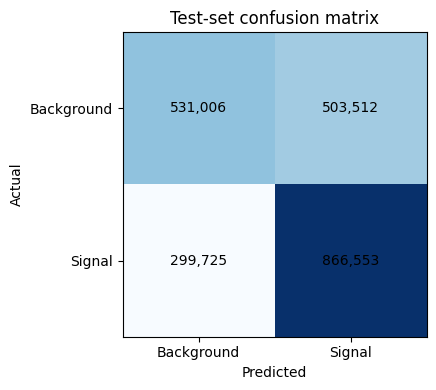

In [ ]:
# Visualization of the aggregate confusion matrix (only 4 cells).
cm = [[tn, fp], [fn, tp]]
fig, ax = plt.subplots(figsize=(5,4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i][j]:,}", ha="center", va="center")
ax.set(xticks=[0,1], yticks=[0,1], xticklabels=["Background", "Signal"],
       yticklabels=["Background", "Signal"], xlabel="Predicted", ylabel="Actual",
       title="Test-set confusion matrix")
plt.tight_layout()
plt.show()

# Coefficients describe association, not causation or nonlinear feature importance.
coefficients = pd.DataFrame({"feature": FEATURES, "coefficient": list(lr_model.coefficients)})
coefficients.to_csv(EXPORT / "model_coefficients.csv", index=False)
# Inputs have different scales, so raw coefficient magnitudes are not directly comparable.


## 9. Example predictions and model persistence
The fitted pipeline produces predicted classes and signal probabilities for 20 held-out simulated events. These `limit(20)` examples illustrate inference and are not a representative evaluation sample. All displayed examples have actual label 0 in this execution; the complete test set contains both classes.

The pipeline is saved and reloaded with `PipelineModel.load`. It is then applied to feature-only rows, demonstrating inference without supplying target labels.


In [ ]:
examples = test.limit(20)
example_predictions = (model.transform(examples)
    .withColumn("probability_signal", vector_to_array("probability")[1])
    .select("label", "prediction", "probability_signal", "lepton_pt", "m_bb", "m_wwbb"))
example_predictions.show(20, truncate=False)
example_predictions.toPandas().to_csv(EXPORT / "example_predictions.csv", index=False)

MODEL_PATH = BASE / "higgs_logistic_pipeline"
model.write().overwrite().save(str(MODEL_PATH))
loaded_model = PipelineModel.load(str(MODEL_PATH))
# Inference accepts features only; a target label is not required.
new_events = test.select(FEATURES).limit(5)
loaded_model.transform(new_events).select(
    "prediction", vector_to_array("probability")[1].alias("probability_signal")
).show(truncate=False)


+-----+----------+-------------------+-------------------+------------------+------------------+
|label|prediction|probability_signal |lepton_pt          |m_bb              |m_wwbb            |
+-----+----------+-------------------+-------------------+------------------+------------------+
|0.0  |0.0       |0.45498397172528415|0.2746966481208801 |0.9728993773460388|0.6895888447761536|
|0.0  |1.0       |0.6029726365214466 |0.2746966481208801 |0.9535737633705139|0.7647550702095032|
|0.0  |0.0       |0.40452870388670137|0.2746966481208801 |1.3504984378814697|0.7627782821655273|
|0.0  |0.0       |0.4855905082882118 |0.2746966481208801 |1.511565923690796 |1.7488341331481934|
|0.0  |1.0       |0.5806882904064586 |0.2746966481208801 |0.6374308466911316|0.8560150861740112|
|0.0  |0.0       |0.4789153662129879 |0.2746966481208801 |1.4830595254898071|1.2718961238861084|
|0.0  |1.0       |0.5389125679017849 |0.2746966481208801 |1.3226479291915894|0.9971383213996887|
|0.0  |0.0       |0.4794901354

## 10. Dashboard data exports
The export tables contain full-test probability-bin counts, dataset and model summaries, and a separate sample of at most 5,000 test predictions. The main dashboard summaries use full-data aggregates. The prediction sample is distinct from the complete evaluation set.


In [ ]:
scored_test = predictions.withColumn("probability_signal", vector_to_array("probability")[1])
confidence = (scored_test.withColumn("probability_bin",
    F.least(F.lit(19), F.floor(F.col("probability_signal") * 20)).cast("int"))
    .groupBy("label", "probability_bin").count()
    .withColumn("bin_start", F.col("probability_bin") / 20.0)
    .withColumn("bin_end", (F.col("probability_bin") + 1) / 20.0))
confidence.orderBy("label", "probability_bin").toPandas().to_csv(EXPORT / "prediction_probability_bins.csv", index=False)

sample_fraction = min(1.0, 10000 / n_test)
(scored_test.select("label", "prediction", "probability_signal")
    .sample(False, sample_fraction, seed=SEED).limit(5000).toPandas()
    .to_csv(EXPORT / "test_predictions_SAMPLE.csv", index=False))

pd.DataFrame([{
    "dataset": "HIGGS", "compressed_GB": size_report["compressed_GB_decimal"],
    "raw_rows": quality["raw_rows"], "valid_rows": quality["valid_rows"],
    "removed_rows": quality["invalid_rows"], "train_rows": n_train, "test_rows": n_test,
    **metrics, "training_seconds": training_seconds
}]).to_csv(EXPORT / "project_overview.csv", index=False)
print("Exported files:")
for file in sorted(EXPORT.iterdir()):
    print(file.name, f"({file.stat().st_size:,} bytes)")


Exported files:
class_distribution.csv (109 bytes)
confusion_matrix.csv (83 bytes)
data_quality.json (823 bytes)
dataset_size_evidence.json (305 bytes)
example_predictions.csv (1,739 bytes)
feature_histograms.csv (14,461 bytes)
feature_means_by_class.csv (1,957 bytes)
feature_summary.csv (4,196 bytes)
model_coefficients.csv (887 bytes)
model_metrics.csv (269 bytes)
prediction_probability_bins.csv (896 bytes)
project_overview.csv (422 bytes)
run_metadata.json (480 bytes)
split_information.json (199 bytes)
test_predictions_SAMPLE.csv (135,497 bytes)


## 11. Result archives and Google Drive backup
The results archive contains dashboard CSV files, measured size evidence and execution metadata. The saved pipeline archive contains the fitted model and its metadata. Both archives are copied to `MyDrive/HIGGS_Project` for persistent storage.


In [ ]:
results_zip = shutil.make_archive(str(BASE / "HIGGS_results"), "zip", root_dir=EXPORT)
model_zip = shutil.make_archive(str(BASE / "HIGGS_saved_model"), "zip",
                               root_dir=BASE, base_dir=MODEL_PATH.name)
print(results_zip)
print(model_zip)
from google.colab import files
files.download(results_zip)


/content/higgs_project/HIGGS_results.zip
/content/higgs_project/HIGGS_saved_model.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Saved pipeline archive download.
files.download(model_zip)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
import shutil

SAVE_DIR = Path("/content/drive/MyDrive/HIGGS_Project")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

shutil.copy2(results_zip, SAVE_DIR / Path(results_zip).name)
shutil.copy2(model_zip, SAVE_DIR / Path(model_zip).name)

print("Results and model saved to:", SAVE_DIR)

Results and model saved to: /content/drive/MyDrive/HIGGS_Project


## 12. Tableau dashboards

The Tableau workbook contains two dashboards based on the Spark-generated summaries.

### Dataset Overview

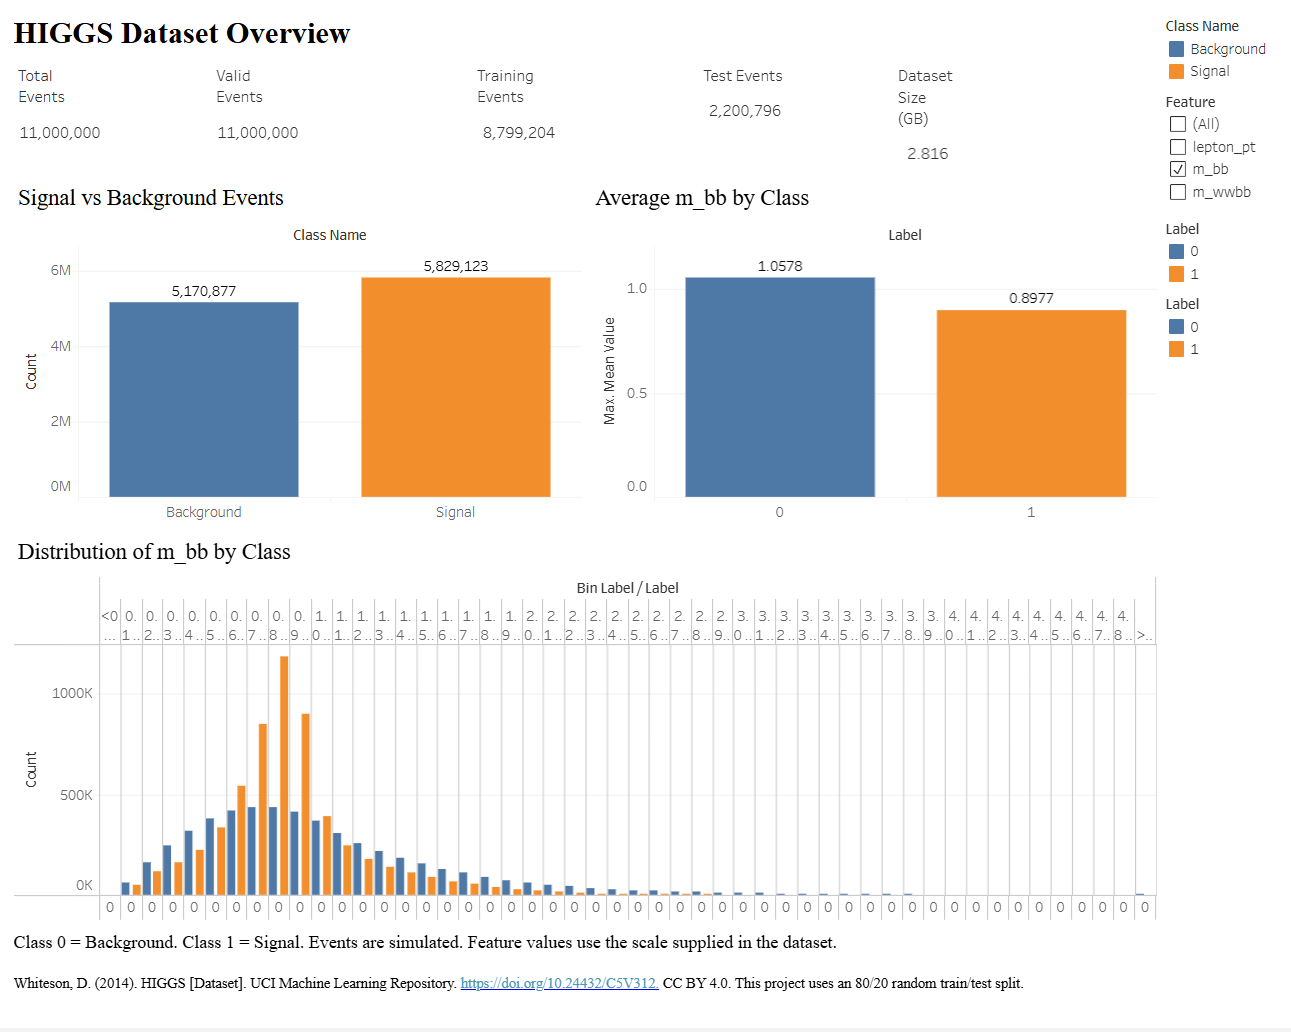

### Model Performance

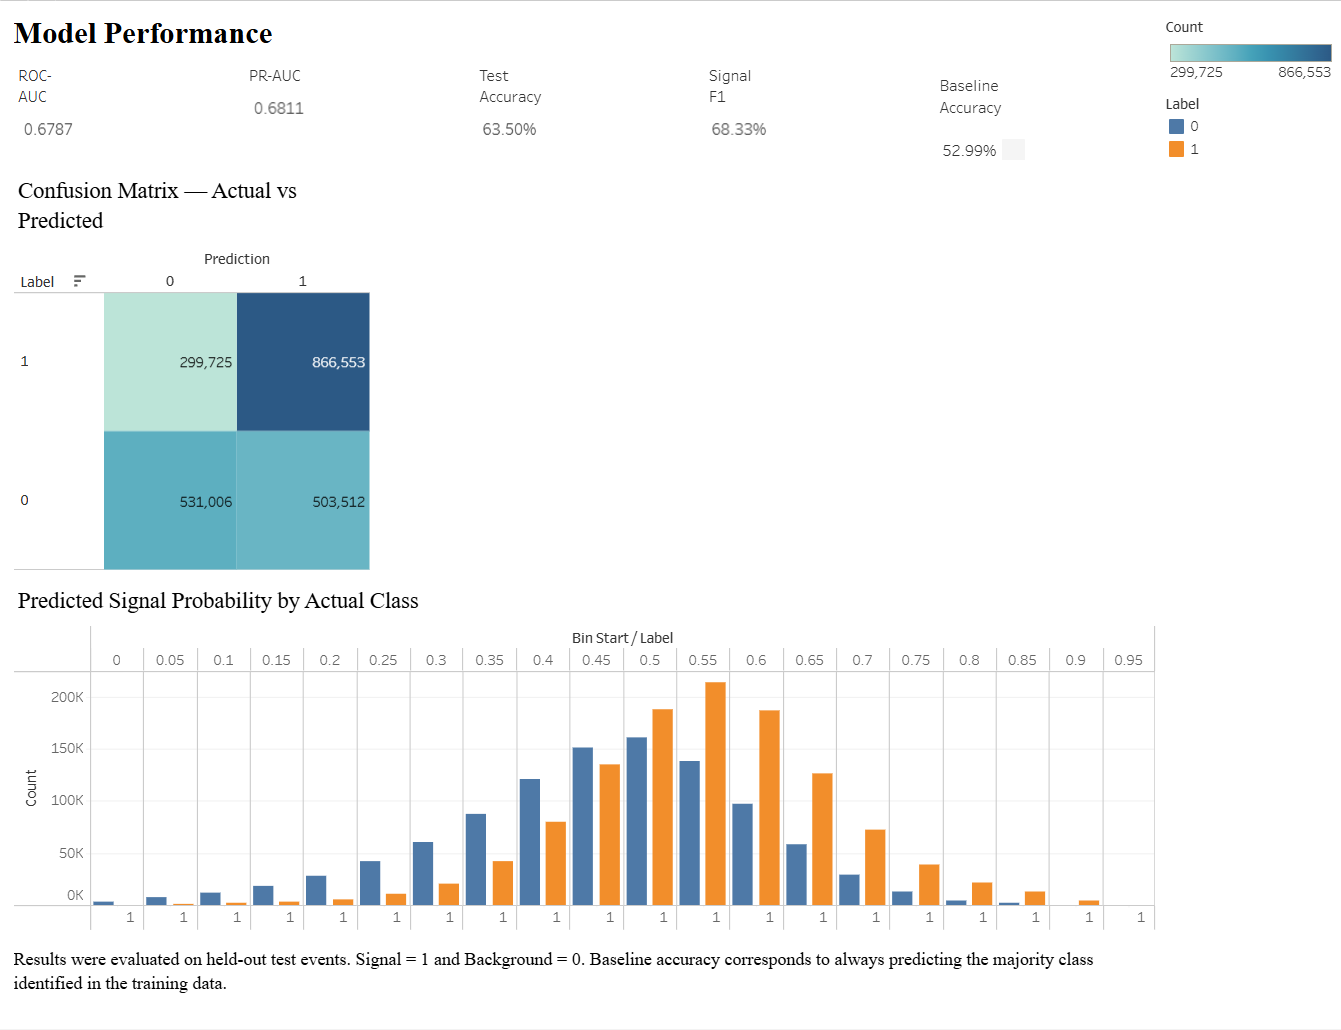


**Dashboard links**

- [Dataset Overview](https://public.tableau.com/views/HIGGSBigDataClassificationDashboard/DatasetOverview?:language=en-US&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)
- [Model Performance](https://public.tableau.com/views/HIGGSBigDataClassificationDashboard/ModelPerformance?:language=en-US&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)

The overview dashboard presents full-dataset counts, feature distributions and class means. The performance dashboard presents held-out metrics, a confusion matrix and prediction probability distributions. Each feature histogram displays one feature, with the same numerical bins used for both classes.


## 13. Results, interpretation and process report

### Problem and dataset
This individual project implemented a Big Data classification workflow using Google Colab, PySpark MLlib and Tableau. The objective was to distinguish signal events (`label = 1`) from background events (`label = 0`) in the HIGGS dataset. The events were generated by Monte Carlo simulation; the classifier does not establish the discovery of a physical particle.

The source dataset contains **11,000,000 events**, **28 numerical predictors** and one target column. The first 21 predictors describe low-level kinematic quantities, while the final seven are derived high-level features. The target was not included in the input feature vector.

| File-size evidence | Observed value |
|---|---:|
| Compressed HIGGS.csv.gz | 2,816,407,858 bytes |
| Compressed size, decimal GB | 2.816407858 GB |
| Compressed size, binary GiB | 2.622984217 GiB |
| Decompressed HIGGS.csv | 8,035,497,980 bytes |
| Decompressed size, decimal GB | 8.035497980 GB |

The downloaded source therefore exceeds the minimum **1 GB** requirement, even before decompression. Decimal GB uses 1,000,000,000 bytes; GiB uses 1,073,741,824 bytes. The decimal and binary units describe the same measured file size using different divisors.

**Dataset citation:** Whiteson, D. (2014). *HIGGS* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5V312. **License:** CC BY 4.0.

### Environment and processing
The saved execution reports **PySpark 3.5.7**, **Python 3.13.16** and the Java installation at `/usr/lib/jvm/java-21-openjdk-amd64`. Spark ran with `local[*]` on a single Colab machine using its available CPU cores. This was not a multi-machine cluster.

The notebook installed the dependencies, mounted Google Drive, downloaded the compressed source in chunks, and decompressed it on Colab's local disk without loading the entire file into Python memory. An explicit schema assigned numerical types to the target and features. The CSV reader reported **60 input partitions** in this run.

Quality checks were applied through Spark aggregations and filters. Valid events were written to Parquet for subsequent processing. The saved execution reports eight Parquet read partitions. Read partitions can differ from the partition count requested before writing because Spark plans file reads separately. Full-data operations remained in Spark; only small summary tables and limited prediction examples were converted to pandas. The generated results and saved-model ZIP archives were copied to Google Drive at `MyDrive/HIGGS_Project`.

### Data quality and descriptive analysis
The workflow checked required fields for nulls, NaN and positive or negative infinity, and rejected target labels outside 0 and 1.

| Quality result | Events |
|---|---:|
| Source rows read | 11,000,000 |
| Invalid rows under the implemented checks | 0 |
| Rows removed | 0 |
| Valid rows retained | 11,000,000 |

No rows required removal under these checks. This establishes numerical completeness and validity for the implemented rules; it does not establish that the dataset is free of every possible quality issue. Signed numerical features were not discarded merely for being negative, and repeated numerical records were not automatically treated as collection errors without event identifiers.

| Class | Events | Share of all valid events |
|---|---:|---:|
| Background (0) | 5,170,877 | 47.0080% |
| Signal (1) | 5,829,123 | 52.9920% |

The classes are relatively close in frequency, with signal as the majority. The dashboard's selected `m_bb` feature has mean **1.0578 for background** and **0.8977 for signal**. This difference describes an association in the supplied feature scale; it is not a causal effect or proof of scientific usefulness. Feature histogram counts for each individual exported feature sum to 11,000,000.

### Train/test separation and model configuration
A seeded random split (`seed = 42`) allocated approximately 80% of valid rows to training and 20% to an unseen test set.

| Partition | Events | Purpose |
|---|---:|---|
| Training | 8,799,204 | Fit model parameters and identify the majority-class baseline |
| Test | 2,200,796 | Evaluate held-out predictions |

The classifier used **all training rows**, rather than a smaller training sample. Its configuration was fixed before test evaluation, and the test set was not used for parameter selection. The split differs from UCI's published benchmark convention of reserving the last 500,000 rows, so these results are not presented as a reproduction of the original benchmark.

The MLlib pipeline combined `VectorAssembler` with binary `LogisticRegression`. The assembler formed a vector from the 28 predictors. Logistic regression used internal standardization, L2 regularization (`regParam = 0.01`, `elasticNetParam = 0.0`), a probability threshold of **0.5**, at most **30 iterations**, and tolerance **1e-5**. This model was selected as a scalable starting classifier for a large numerical dataset, with interpretable coefficients and a relatively inexpensive training procedure.

The recorded fitting time was **147.65 seconds** (about **2.46 minutes**). The optimizer completed **20 iterations**, below its configured limit of 30, with final training objective **0.6451032300581353**. The objective is the optimization criterion, not an accuracy score. Fitting time excludes downloading, preprocessing, evaluation and dashboard creation.

### Evaluation on held-out events
Spark's `BinaryClassificationEvaluator` computed ROC-AUC and PR-AUC from continuous prediction scores. `MulticlassClassificationEvaluator` computed accuracy and weighted F1. Signal-class precision, recall and F1 were derived from the confusion matrix aggregated in PySpark.

| Test metric | Observed result |
|---|---:|
| ROC-AUC | 0.678668 |
| PR-AUC | 0.681133 |
| Accuracy | 63.5024% |
| Weighted F1 | 0.629749 |
| Signal precision | 63.2490% |
| Signal recall | 74.3007% |
| Signal F1 | 0.683309 |
| Majority-class baseline accuracy | 52.9935% |

The confusion matrix covers all **2,200,796 test events**:

| Actual class | Predicted background (0) | Predicted signal (1) |
|---|---:|---:|
| Background (0) | 531,006 — true negatives | 503,512 — false positives |
| Signal (1) | 299,725 — false negatives | 866,553 — true positives |

The model correctly classified **1,397,559 events** and misclassified **803,237 events**. Its accuracy exceeded the always-majority baseline by **10.51 percentage points**. The baseline class was determined from training data and was signal; its test accuracy is therefore the test-set signal prevalence, approximately 52.99%.

Signal recall of **74.30%** means the model identified about three quarters of actual signal events. Signal precision of **63.25%** means that about 63 of every 100 events classified as signal were actual signal. There were **503,512 false positives**, where background was classified as signal, and **299,725 false negatives**, where actual signal was missed. Signal F1 balances this precision and recall and differs from the weighted F1 calculated over both classes.

ROC-AUC of **0.6787** indicates some discrimination beyond random ranking, but the separation is moderate. PR-AUC was **0.6811**, compared with an approximately **0.5299** signal prevalence; it measures precision-recall performance rather than classification accuracy. For a preliminary signal-screening objective, recall helps quantify missed candidates; the false-positive burden and the intended follow-up process must also be considered. The current results support a useful baseline experiment, not a claim of high-accuracy or production-ready scientific classification.

### Predictions and saved model
The notebook generated classes and signal probabilities for 20 held-out examples. At the fixed threshold of 0.5, a probability above 0.5 is classified as signal and a probability below 0.5 as background. Examples from the exported file include:

| Displayed example | Actual class | Signal probability | Predicted class | Outcome |
|---|---:|---:|---:|---|
| 1 | 0 | 0.454984 | 0 | Correct background |
| 2 | 0 | 0.602973 | 1 | False positive |
| 3 | 0 | 0.404529 | 0 | Correct background |

The displayed examples are selected with `limit(20)`; they are not a random or representative sample, and all 20 happen to have actual label 0 in this run. They illustrate inference rather than estimate performance. Evaluation used the complete test set containing both classes. The separate **5,000-row** exported prediction sample contains **2,384 background** and **2,616 signal** events and is labeled as a sample.

The complete fitted pipeline was saved, reloaded with `PipelineModel.load`, and applied to five feature-only held-out rows without providing target labels. This demonstrates reusable inference with the saved model. The predictions and reported evaluation use held-out events from HIGGS; independent external-data validation was outside the scope of this experiment.

### Tableau visualization and interpretation
The hosted visualization was built in **Tableau**, using Spark-generated CSV summaries. The **Dataset Overview** dashboard includes row counts, the measured compressed dataset size, class counts, class-specific feature means and a single-feature distribution. The **Model Performance** dashboard includes ROC-AUC, PR-AUC, accuracy, signal F1, baseline accuracy, a confusion matrix and prediction probability distributions. The screenshots in Section 12 document the dashboard views.

[Dataset Overview](https://public.tableau.com/views/HIGGSBigDataClassificationDashboard/DatasetOverview?:language=en-US&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)

[Model Performance](https://public.tableau.com/views/HIGGSBigDataClassificationDashboard/ModelPerformance?:language=en-US&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)

The source summaries use all valid rows; the evaluation summaries use all test rows. Tableau receives aggregate tables instead of the entire raw dataset, which keeps the visualization manageable while retaining full-data counts. The `m_bb` means show differences between classes, while the prediction probability distributions overlap substantially. This overlap is consistent with the model's moderate AUC and the presence of both false positives and false negatives. Each feature-distribution view displays a single selected variable, with class-specific counts in the corresponding bins.

### Limitations, potential improvements and conclusion
Logistic regression uses a linear score and may miss nonlinear interactions among the low-level and derived features. The simulation setting limits direct claims about real detector data. Numerical validity checks do not establish domain validity, and predicted probabilities were not separately assessed for calibration. Different input scales prevent direct comparison of raw coefficient magnitudes as a feature-importance ranking. Local Colab execution demonstrates Spark processing of a large dataset but does not demonstrate scaling across multiple machines.

Potential extensions include nonlinear MLlib classifiers, parameter tuning with a validation partition, and probability calibration analysis. Threshold selection would depend on the desired precision/recall tradeoff. A separate untouched final holdout would support evaluation after iterative model development.

The completed workflow processed the full dataset, retained 11 million valid events, trained an MLlib classifier, evaluated 2,200,796 held-out events, generated example predictions, saved and reloaded the model, and produced Tableau dashboard evidence. The test accuracy of 63.50% exceeded the 52.99% majority baseline while leaving substantial classification error to address in future work.

In this [repository](https://github.com/LechBCS/LechCow-BCS), you can find the same notebook and the final work of our team.
